# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1051]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [1052]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [1053]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


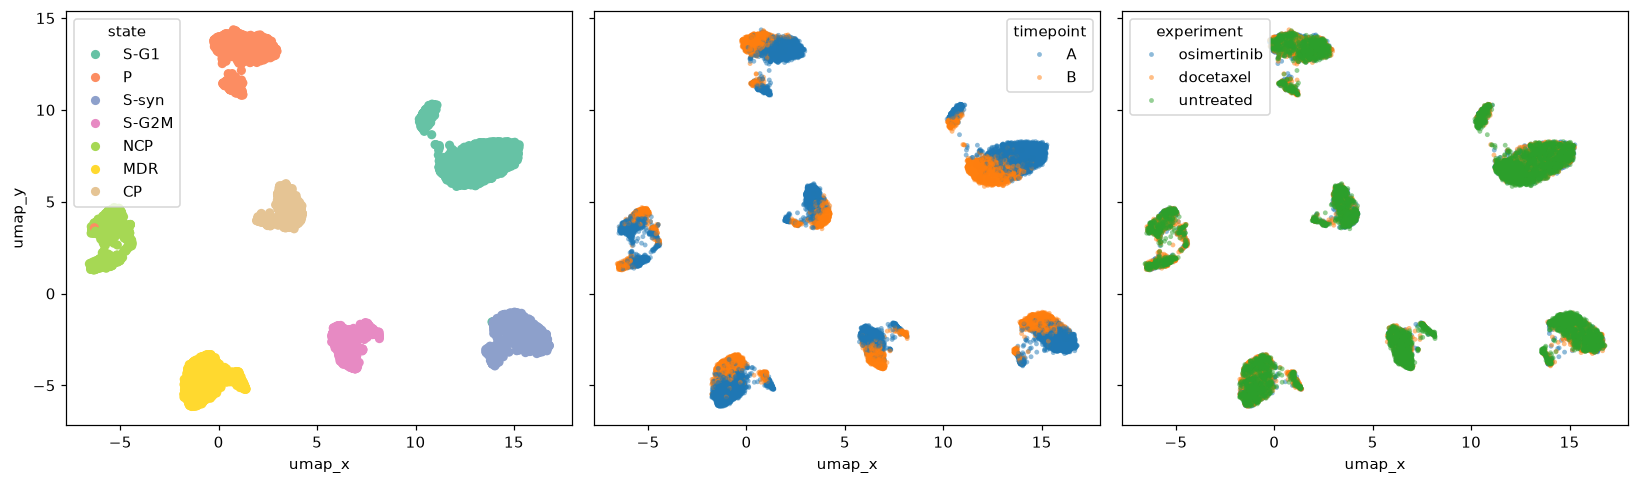

In [1054]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [1055]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [1056]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [1057]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [1058]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [1059]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [1060]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

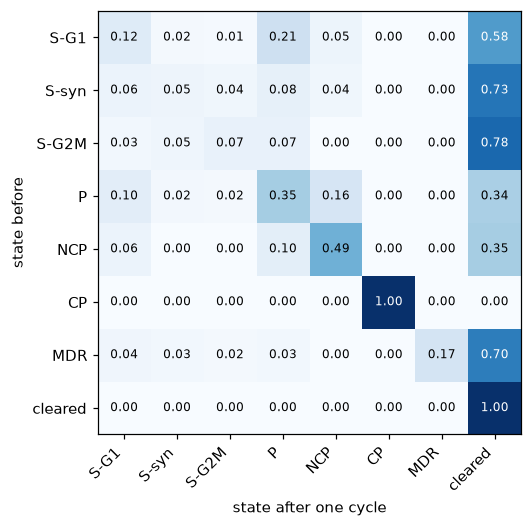

In [1061]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

The CP state is also absorbing; this can be view row-wisely, where any before CP state remains at CP with probability 1. In context, this means the application of osimertinib does not empricially change the state of CP cells. There are limitations of this conclusion, though. For one, it is possible that the cell may change in ways that are not reflected in the label, which may be good or bad. Similarly, just because the application of medication changes the states for certain cell types does not neccesarily mean this change is good; it is possible that staying in the same CP state may be a better outcome than progressing to a different cell type. 

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

Based on our starting point of $e$, we can never arrive at state CP or MDR. This is confirmed by iteratively checking neighbors, NOT just the single transition. However, S-G1 can still arrive at S-G1, S-syn, S-G2M, P, NCP, and cleared (in fact, it can directly reach all of these).

In [1062]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [1063]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [1064]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


We do not clear all of the cancer cells; 0.989 are cleared. The remaining are dispersed across S-G1, S-syn, S-G2M, P, and NCP. Notice that none of the CP or MDR are present, as anticipated. 

The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

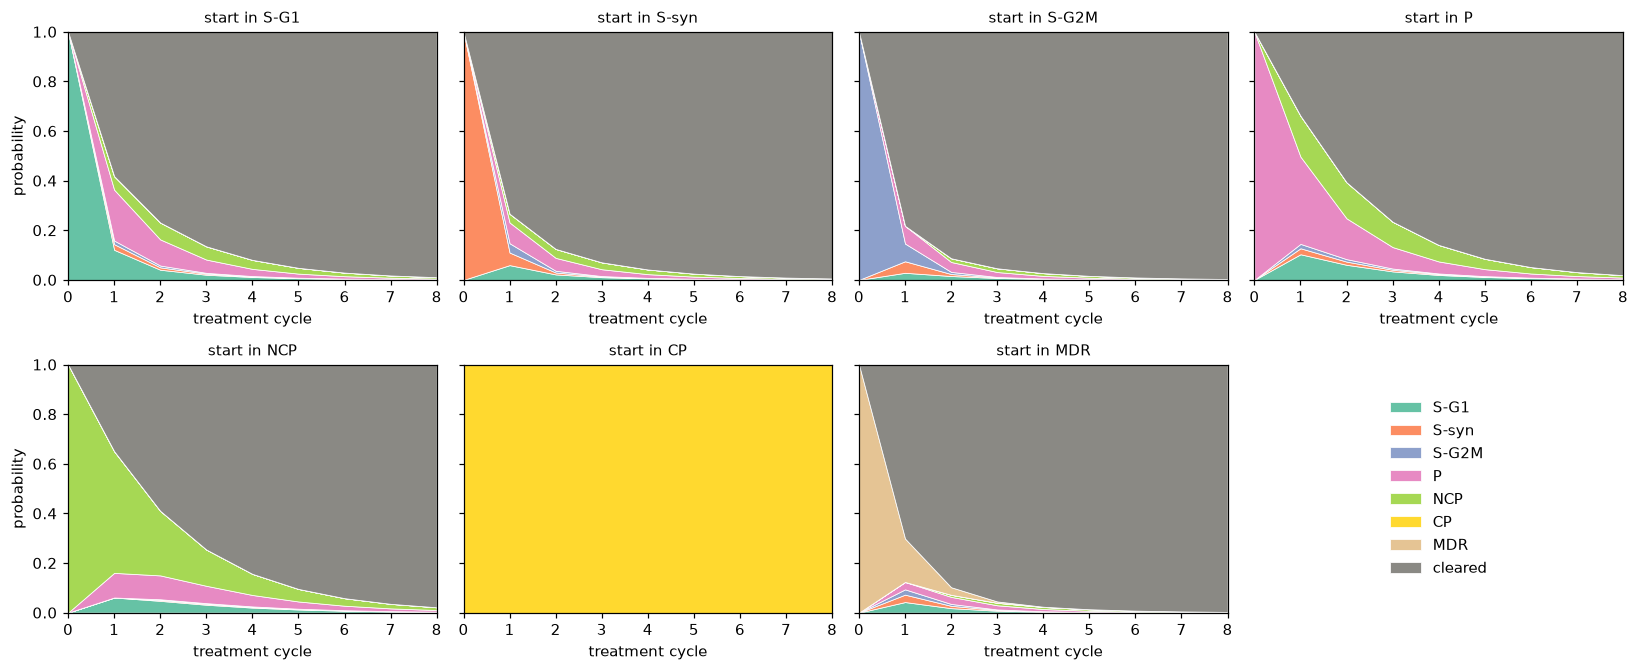

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [1065]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



In [1066]:
for s in STATES:
    traj = evolve(basis(s, P_hat), P_hat, N_CYCLES)
    print(f"8 Cycles with Starting State: {s}")
    print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
    print()

8 Cycles with Starting State: S-G1
    S-G1  S-syn  S-G2M      P    NCP   CP  MDR  cleared
0  1.000  0.000  0.000  0.000  0.000  0.0  0.0    0.000
1  0.121  0.023  0.015  0.205  0.055  0.0  0.0    0.582
2  0.041  0.010  0.007  0.105  0.068  0.0  0.0    0.769
3  0.021  0.004  0.003  0.054  0.053  0.0  0.0    0.865
4  0.012  0.002  0.002  0.029  0.036  0.0  0.0    0.919
5  0.007  0.001  0.001  0.016  0.023  0.0  0.0    0.951
6  0.004  0.001  0.000  0.010  0.015  0.0  0.0    0.971
7  0.002  0.000  0.000  0.006  0.009  0.0  0.0    0.982
8  0.001  0.000  0.000  0.003  0.005  0.0  0.0    0.989

8 Cycles with Starting State: S-syn
    S-G1  S-syn  S-G2M      P    NCP   CP  MDR  cleared
0  0.000  1.000  0.000  0.000  0.000  0.0  0.0    0.000
1  0.059  0.051  0.037  0.084  0.035  0.0  0.0    0.733
2  0.022  0.008  0.007  0.052  0.036  0.0  0.0    0.875
3  0.011  0.002  0.002  0.028  0.028  0.0  0.0    0.929
4  0.006  0.001  0.001  0.015  0.019  0.0  0.0    0.958
5  0.004  0.001  0.000  0.009  0

In [1067]:
alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 3)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 3 cycles, starting in", s, ":", round(v, 3))

fraction alive after 3 cycles, starting in S-G1 : 0.135
fraction alive after 3 cycles, starting in S-syn : 0.071
fraction alive after 3 cycles, starting in S-G2M : 0.047
fraction alive after 3 cycles, starting in P : 0.234
fraction alive after 3 cycles, starting in NCP : 0.254
fraction alive after 3 cycles, starting in CP : 1.0
fraction alive after 3 cycles, starting in MDR : 0.045
fraction alive after 3 cycles, starting in cleared : 0.0


I have explicitly written out the trajectory matrices. To answer the first question, we just need to consider the final row of each matrix. Technically, none of the starting states are completely eliminated by 8 cycles of osimertinib, but S-G1, S-Syn, S-G2M, and MDR all have values of approximately 0.99 or above; P and NCP lag behind at about 0.98, and CP is the worst at 0. For the purposes of this question, I will take the first group to be "cleared". Of these states that can be cleared, S-G1 appears to stick around the longest; this is most easily seen in the plot, where the S-G1 tail remains much fatter than the S-Syn, S-G2M, and MDR. If, alternatively, I was supposed to include P and NCP in cleared, then these two actually have fatter tails, with NCP being slightly fatter. Clearly, CP is the starting state that sticks around for the most cycles of the drug, remaining unchanged (all proportion of cells remain CP) throughout; technically, it also results in the highest proportion fo alive cells, since all cells remain alive.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

In [1068]:
osi[osi.timepoint == "A"]["state"].value_counts(normalize=True).reindex(STATE_ORDER)

state
S-G1     0.250333
S-syn    0.151333
S-G2M    0.093333
P        0.151667
NCP      0.104000
CP       0.093000
MDR      0.156333
Name: proportion, dtype: float64

In [1069]:
np.append(
    osi[osi.timepoint == "A"]["state"].value_counts(normalize=True).reindex(STATE_ORDER).to_numpy(),
    0
)

array([0.25033333, 0.15133333, 0.09333333, 0.15166667, 0.104     ,
       0.093     , 0.15633333, 0.        ])

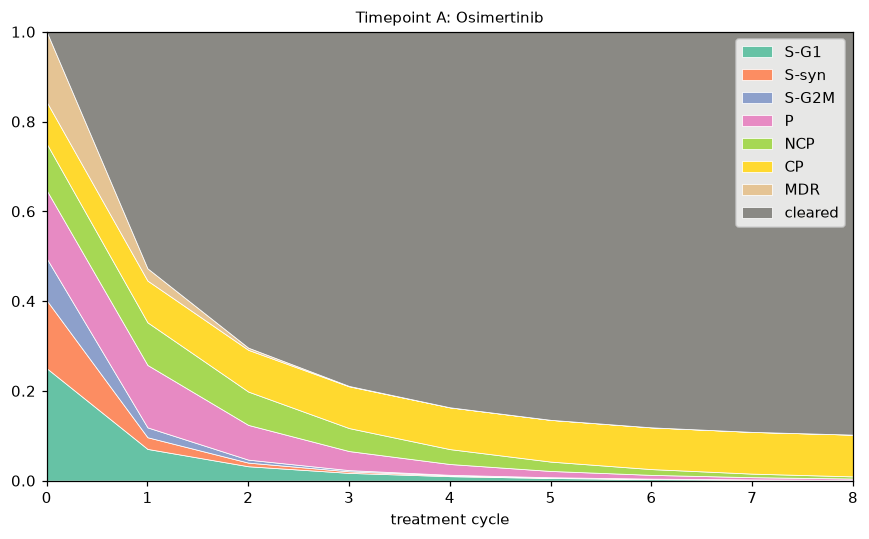

In [1070]:
# Your code here
pi_mix = np.append(
    osi[osi.timepoint == "A"]["state"].value_counts(normalize=True).reindex(STATE_ORDER).to_numpy(),
    0
)

# evolve pi_mix and plot the results
fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(evolve(pi_mix, P_hat, N_CYCLES), ax, "Timepoint A: Osimertinib")
                                
plt.legend()
plt.tight_layout()
plt.show()

In [1071]:
traj = evolve(pi_mix, P_hat, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.250  0.151  0.093  0.152  0.104  0.093  0.156    0.000
1  0.071  0.026  0.022  0.139  0.095  0.093  0.027    0.527
2  0.032  0.008  0.007  0.077  0.074  0.093  0.005    0.704
3  0.017  0.003  0.003  0.042  0.051  0.093  0.001    0.789
4  0.010  0.002  0.001  0.024  0.033  0.093  0.000    0.837
5  0.006  0.001  0.001  0.014  0.021  0.093  0.000    0.865
6  0.004  0.001  0.000  0.008  0.013  0.093  0.000    0.881
7  0.002  0.000  0.000  0.005  0.008  0.093  0.000    0.891
8  0.001  0.000  0.000  0.003  0.005  0.093  0.000    0.898



<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

The remaining cluster is dominated by CP, which makes up about 0.093 of the total cells and over $90\%$ of the alive ones. These cells will never be cleared because CP is an absorbing state; it transitions to itself with probability 1. More broadly, the long-run endpoint is directly tied to the transition matrix (and, depending on the attributes of our transition matrix, the starting vector). Absorbing points are an extreme attribute of a transition matrix that "fix" probability mass. In effect, any mass that finds itself in an absorbing strate is indefinitely constrained to that state. In this way, part of the initial probability mass has "converged" when it arrives in the absorbing state. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [1072]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat

doc = cells[cells["experiment"] == "docetaxel"]
at_A = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B = doc[doc.timepoint == "B"][["lineage_tag", "state"]]
pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = counts.div(counts.sum(axis=1), axis=0)

holiday = cells[cells["experiment"] == "untreated"]
at_A = holiday[holiday.timepoint == "A"][["lineage_tag", "state"]]
at_B = holiday[holiday.timepoint == "B"][["lineage_tag", "state"]]
pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hol = counts.div(counts.sum(axis=1), axis=0)

Osi:

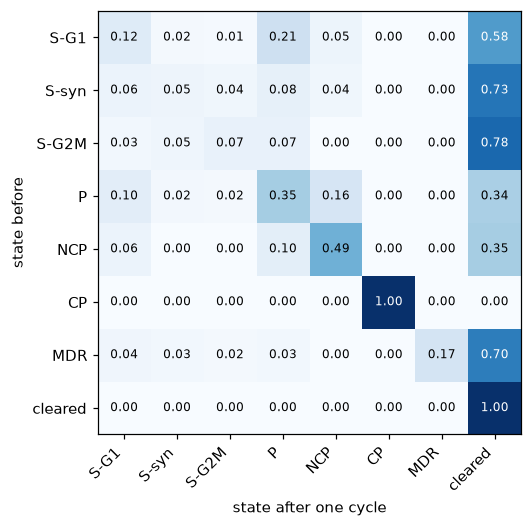

In [1073]:
#Plot the transition matrices for docetaxel and the drug holiday.
show_matrix(P_osi)

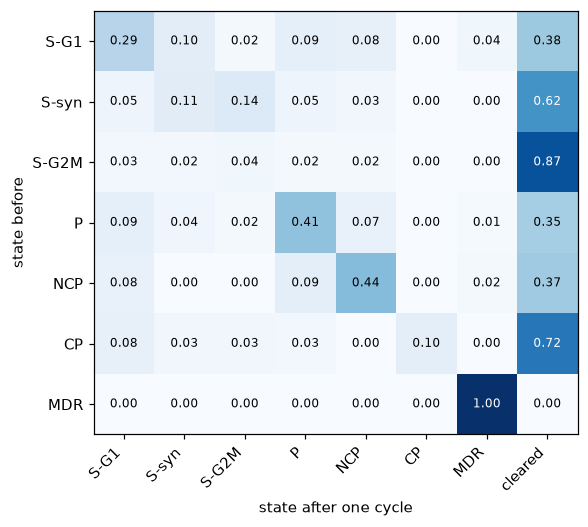

In [1074]:
show_matrix(P_doc)

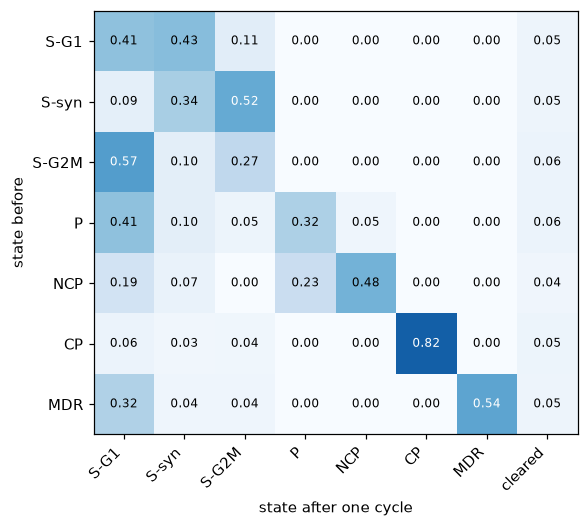

In [1075]:
show_matrix(P_hol)

In [1076]:
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})

In [1077]:
P_hol.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hol.columns})

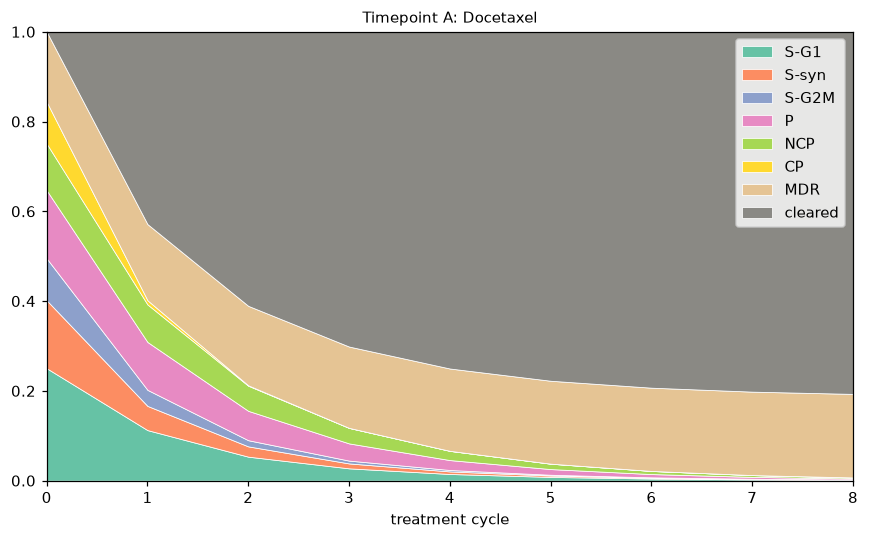

In [1078]:
# evolve pi_mix and plot the results
fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(evolve(pi_mix, P_doc, N_CYCLES), ax, "Timepoint A: Docetaxel")
                                
plt.legend()
plt.tight_layout()
plt.show()

In [1079]:
# Simulate the evolution of pi_mix under docetaxel 
traj = evolve(pi_mix, P_doc, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.250  0.151  0.093  0.152  0.104  0.093  0.156    0.000
1  0.113  0.054  0.036  0.107  0.084  0.009  0.170    0.429
2  0.053  0.023  0.014  0.065  0.056  0.001  0.177    0.611
3  0.027  0.011  0.006  0.038  0.035  0.000  0.181    0.701
4  0.015  0.006  0.003  0.022  0.021  0.000  0.183    0.750
5  0.008  0.003  0.002  0.013  0.012  0.000  0.185    0.777
6  0.005  0.002  0.001  0.007  0.007  0.000  0.185    0.793
7  0.003  0.001  0.001  0.004  0.004  0.000  0.186    0.802
8  0.002  0.001  0.000  0.002  0.002  0.000  0.186    0.807



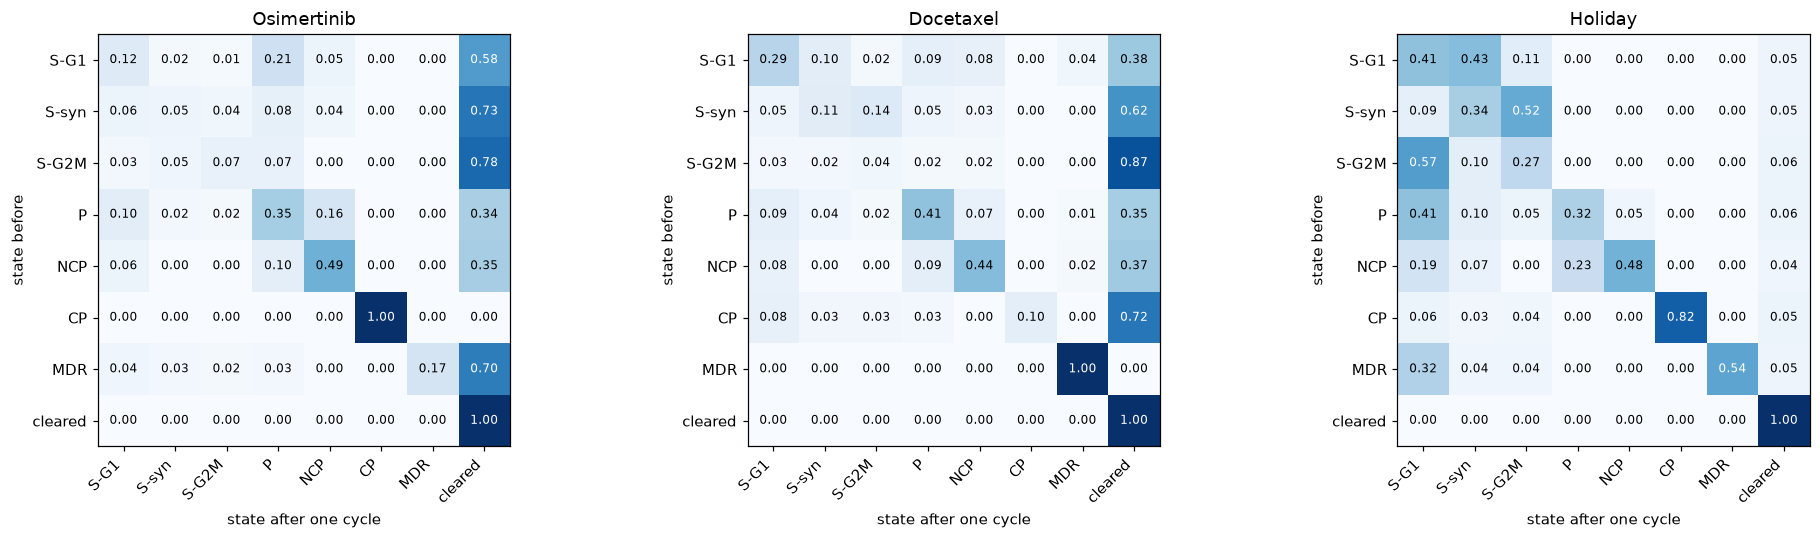

In [1080]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

show_matrix(P_osi, title="Osimertinib", ax=axes[0])
show_matrix(P_doc, title="Docetaxel", ax=axes[1])
show_matrix(P_hol, title="Holiday", ax=axes[2])

plt.tight_layout()
plt.show()

Above is the side-by-side display of all the transition matrices. In the broad strokes, Osimertnib and Docetaxel share a lot in common and differ significantly from the holiday. For one, Osimertnib and Docetaxel showcase a similar vertical striping in the cleared column, which holiday does not have. In context, this means both drug medications tend to transition most cell states to cleared at a higher rate than drug holiday does; the exception is CP and MDR for Osimertib and Docetaxel, respectively. On the other hand, the holiday transition matrix has a more pronounced diagonal and a more pronounced first column. The pronounced diagonal implies that, across all states, cells tend to remain in the same state compared to the treatment groups. Likewise, the pronounced first column suggests that all cell types tend to transition to S-G1 at a higher rate than the two treatment groups. Apart from the cleared absorbing state, the holiday schedule does not have any additional absorbing states. This absence of a second absorption state contrasts with Osimertib, which has an additional absorbing state of CP, and Docetaxel, which has an additional absorbing state of MDR; in many ways, Docetaxel and Osimertib behave more or less identically, so long as we relabel MDR as CP and CP as MDR in one of the cases. One small difference is that docetaxel can introduce resistant cells (MDR), whereas osternib does not. The absence of a second absorbing state presents a unique use case for the holiday; after the application of one of the treatments, the holiday may help to push states out of their absorbing states. 

Under the same 8 cycles, docetaxel performs slightly worse on the original tumor. Moreover, only about $75\%$ of the tumor cells are cleared, and $18.3\$% remain in the concerning resistant state of MDR; roughly $7\%$ are scattered across the reamining cell states (excluding CP). This contrasts with 8 cycles of osternib, which cleared $89.8\%$ of the tumor cells, and only $9.3\%$ remain in the concerning resistant state of CP; roughly $1\%$ are scattered across the remaining cell states (excluding MDR). Generally, docetaxel's worse performance stems from the original tumor composition. Docetaxel can handle CP states well, but it cannot handle MDR states well. Since MDR makes up a larger proportion of the original tumor, repeated application of docetaxel cannot address this segment. 


## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [1081]:
P_osi_n = np.array(P_osi)
P_doc_n = np.array(P_doc)
P_hol_n = np.array(P_hol)

In [1082]:
P_osi_n @ P_doc_n

array([[0.05969856, 0.02339757, 0.01054216, 0.1014356 , 0.04974271,
        0.        , 0.00848777, 0.74669562],
       [0.03123816, 0.01595895, 0.01130403, 0.04626945, 0.02874913,
        0.        , 0.00410254, 0.86237774],
       [0.01915765, 0.01268767, 0.01092601, 0.03563177, 0.01055661,
        0.        , 0.00205753, 0.90898275],
       [0.07612076, 0.02765879, 0.01390984, 0.17024097, 0.10718863,
        0.        , 0.0124266 , 0.5924544 ],
       [0.0637231 , 0.01016328, 0.00486137, 0.09227978, 0.22593352,
        0.        , 0.01437016, 0.5886688 ],
       [0.07931034, 0.03448276, 0.03448276, 0.02758621, 0.        ,
        0.1       , 0.        , 0.72413793],
       [0.01729917, 0.00938436, 0.00631623, 0.01802812, 0.00706697,
        0.        , 0.17678459, 0.76512055],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 1.        ]])

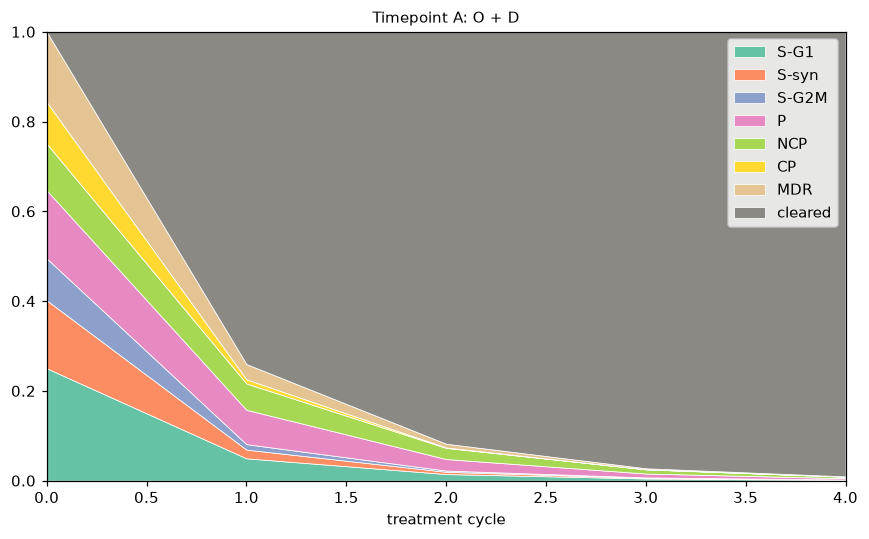

In [1083]:
N_CYCLES = 4

# evolve pi_mix and plot the results
fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(evolve(pi_mix, P_osi_n @ P_doc_n, N_CYCLES), ax, "Timepoint A: O + D")
                                
plt.legend()
plt.tight_layout()
plt.show()

In [1084]:
traj = evolve(pi_mix, P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.250  0.151  0.093  0.152  0.104  0.093  0.156    0.000
1  0.050  0.019  0.012  0.077  0.059  0.009  0.034    0.740
2  0.015  0.005  0.003  0.026  0.025  0.001  0.008    0.918
3  0.005  0.002  0.001  0.009  0.009  0.000  0.002    0.972
4  0.002  0.001  0.000  0.003  0.003  0.000  0.001    0.991



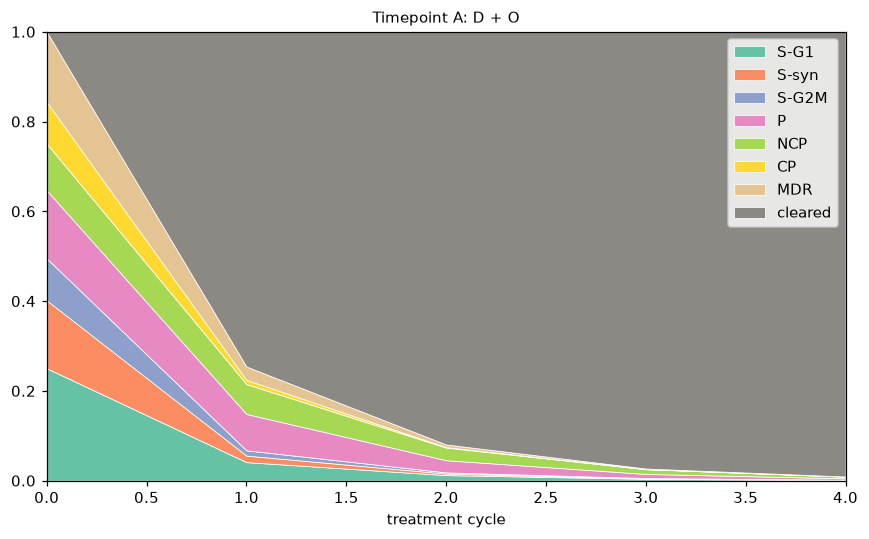

In [1085]:
N_CYCLES = 4

# evolve pi_mix and plot the results
fig, ax = plt.subplots(figsize=(8, 5))
plot_trajectory(evolve(pi_mix, P_doc_n @ P_osi_n, N_CYCLES), ax, "Timepoint A: D + O")
                                
plt.legend()
plt.tight_layout()
plt.show()

In [1086]:
traj = evolve(pi_mix, P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.250  0.151  0.093  0.152  0.104  0.093  0.156    0.000
1  0.041  0.015  0.012  0.081  0.067  0.009  0.030    0.746
2  0.012  0.003  0.003  0.027  0.028  0.001  0.006    0.919
3  0.004  0.001  0.001  0.009  0.011  0.000  0.001    0.973
4  0.001  0.000  0.000  0.003  0.004  0.000  0.000    0.991



In the broad strokes, the two orders of application result in more or less the same outcome; about $99.1\%$ of the tumor cells are cleared, and the majority of the remaining lives cells are in S-G1, P, and NCP. Still, the docetaxel-ostinerib performs marginally better in the sense that both CP and MDR are 0, whereas MDR remains 0.001 in ostinerib-docetaxel strategy. 

A drug holiday may obviously have many possible use cases, but one observation is that neither CP nor MDR are truly absorbing states, and holiday is in particular moderately effective at transitioning MDR to S-G1; it also does not transition any states to MDR or CP. In this way, holiday can serve as a recomposition tool, helping to shift "stuck" cells, such as those in MDR or CP, out of these states after applying the respective treatment where it is an absorbing state. Note that it is not nearly as effective in this role as just applying the other treatment afterward instead, but, especially for handling MDR cells (that is, after application of docetaxel), it may be effective enough that the health/financial trade-off of less medication (for example, not applying osimertnib) is worth it. 

In [1087]:
S_G1 = basis("S-G1", P_hat)
S_syn = basis("S-syn", P_hat)
S_G2M = basis("S-G2M", P_hat)
P = basis("P", P_hat)
NCP = basis("NCP", P_hat)
CP = basis("CP", P_hat)
MDR = basis("MDR", P_hat)

### Case 1: Balanced Distribution Across Non-Resistant Cells

In [1088]:
bal_nonres = 0.2 * S_G1 + 0.2 * S_syn + 0.2 * S_G2M + 0.2 * P + 0.2 * NCP

In [1089]:
N_CYCLES = 8

traj = evolve(bal_nonres, P_hol, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP  MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.0    0.000
1  0.335  0.208  0.190  0.110  0.105  0.0  0.0    0.052
2  0.330  0.253  0.201  0.059  0.055  0.0  0.0    0.101
3  0.309  0.259  0.223  0.032  0.029  0.0  0.0    0.148
4  0.297  0.249  0.229  0.017  0.015  0.0  0.0    0.193
5  0.286  0.239  0.223  0.009  0.008  0.0  0.0    0.235
6  0.273  0.229  0.215  0.005  0.004  0.0  0.0    0.275
7  0.259  0.218  0.205  0.002  0.002  0.0  0.0    0.313
8  0.246  0.207  0.196  0.001  0.001  0.0  0.0    0.349



In [1090]:
N_CYCLES = 8

traj = evolve(bal_nonres, P_osi, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP  MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.0    0.000
1  0.075  0.029  0.028  0.162  0.149  0.0  0.0    0.557
2  0.037  0.008  0.007  0.092  0.105  0.0  0.0    0.751
3  0.021  0.004  0.003  0.052  0.069  0.0  0.0    0.852
4  0.012  0.002  0.002  0.030  0.044  0.0  0.0    0.911
5  0.007  0.001  0.001  0.018  0.027  0.0  0.0    0.946
6  0.004  0.001  0.001  0.011  0.017  0.0  0.0    0.967
7  0.003  0.000  0.000  0.006  0.010  0.0  0.0    0.980
8  0.002  0.000  0.000  0.004  0.006  0.0  0.0    0.988



In [1091]:
N_CYCLES = 8

traj = evolve(bal_nonres, P_doc, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.107  0.056  0.043  0.133  0.129  0.0  0.014    0.518
2  0.057  0.023  0.014  0.080  0.077  0.0  0.023    0.725
3  0.031  0.012  0.007  0.047  0.045  0.0  0.028    0.830
4  0.018  0.007  0.004  0.027  0.026  0.0  0.031    0.888
5  0.010  0.004  0.002  0.015  0.015  0.0  0.032    0.921
6  0.006  0.002  0.001  0.009  0.009  0.0  0.033    0.940
7  0.003  0.001  0.001  0.005  0.005  0.0  0.034    0.951
8  0.002  0.001  0.000  0.003  0.003  0.0  0.034    0.957



In [1092]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.040  0.011  0.009  0.090  0.093  0.0  0.003    0.755
2  0.013  0.003  0.002  0.030  0.035  0.0  0.001    0.917
3  0.004  0.001  0.001  0.010  0.012  0.0  0.001    0.971
4  0.001  0.000  0.000  0.003  0.004  0.0  0.000    0.990



In [1093]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.050  0.018  0.010  0.089  0.084  0.0  0.008    0.740
2  0.016  0.005  0.003  0.029  0.032  0.0  0.004    0.911
3  0.006  0.002  0.001  0.010  0.011  0.0  0.002    0.969
4  0.002  0.001  0.000  0.003  0.004  0.0  0.001    0.989



In [1094]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_hol_n @ P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.045  0.018  0.010  0.079  0.060  0.0  0.007    0.781
2  0.011  0.004  0.002  0.020  0.016  0.0  0.002    0.944
3  0.003  0.001  0.001  0.005  0.004  0.0  0.001    0.986
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1095]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_hol_n @ P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.038  0.011  0.010  0.080  0.071  0.0  0.003    0.787
2  0.009  0.003  0.002  0.021  0.020  0.0  0.001    0.944
3  0.002  0.001  0.001  0.005  0.005  0.0  0.000    0.985
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1096]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_osi_n @ P_hol_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.061  0.027  0.016  0.060  0.055  0.0  0.008    0.772
2  0.016  0.007  0.004  0.016  0.015  0.0  0.003    0.940
3  0.004  0.002  0.001  0.004  0.004  0.0  0.001    0.984
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1097]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_doc_n @ P_hol_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.038  0.013  0.011  0.077  0.057  0.0  0.001    0.802
2  0.010  0.003  0.003  0.020  0.015  0.0  0.001    0.950
3  0.002  0.001  0.001  0.005  0.004  0.0  0.000    0.987
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.997



In [1098]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_doc_n @ P_osi_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.078  0.037  0.017  0.050  0.048  0.0  0.002    0.767
2  0.021  0.010  0.005  0.013  0.013  0.0  0.001    0.938
3  0.006  0.003  0.001  0.004  0.003  0.0  0.000    0.983
4  0.001  0.001  0.000  0.001  0.001  0.0  0.000    0.996



In [1099]:
N_CYCLES = 4

traj = evolve(bal_nonres, P_osi_n @ P_doc_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.200  0.200  0.200  0.200  0.200  0.0  0.000    0.000
1  0.083  0.044  0.023  0.048  0.044  0.0  0.005    0.753
2  0.022  0.012  0.006  0.012  0.011  0.0  0.002    0.935
3  0.006  0.003  0.002  0.003  0.003  0.0  0.000    0.983
4  0.001  0.001  0.000  0.001  0.001  0.0  0.000    0.996



In the case where the original tumor cell contains no resistant cells, there are two clear winners. For the most non-invasive treatment, one could opt for repeated holidays, and the results are somewhat promising; no resistant cells are introduced, and about $35\%$ clear on their own. Obviously, this is not nearly as effective as the medications, but it comes with less invasion. Of the two medications, ostinerib appears clearly the better choice; not only does it remove $98.8\%$ of the cells, but it does not introduce any resistant cells. These results also inspire a possible alternation. As the results indicate above, alternation (doc then osi) is the most effective of the two, and it makes sense that this ordering is slightly more effective than the opposite ordering; doc will introduce resistant MDR cells, but osi can eliminate them. Of the three alternations, doc, holiday, and osi yields the best return with $99.7\%$ clearance and no resitant strains. 

Across all treatment combinations, it is clear that there are somewhat diminishing returns; by about four total treatments (row 2 for the alternations), most treatments are approaching $90\%$ clear, and the marginal gains rapidly decrease. As such, I would probably recommend D-H-O (as anticipated in last section!) for four total treatments, though I think all holidays would be conservative and not a horrible idea.

### Case 2: Balanced Distribution Across Non-Resistant Cells (+ CP)

In [1100]:
bal_cp = (1/6) * S_G1 + (1/6) * S_syn + (1/6) * S_G2M + (1/6) * P + (1/6) * NCP + (1/6) * CP

In [1101]:
N_CYCLES = 8

traj = evolve(bal_cp, P_hol, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP  MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.0    0.000
1  0.289  0.179  0.164  0.092  0.087  0.137  0.0    0.052
2  0.291  0.222  0.178  0.050  0.046  0.112  0.0    0.102
3  0.278  0.231  0.200  0.026  0.024  0.092  0.0    0.148
4  0.271  0.226  0.208  0.014  0.013  0.075  0.0    0.193
5  0.264  0.220  0.205  0.007  0.007  0.062  0.0    0.235
6  0.254  0.213  0.200  0.004  0.004  0.051  0.0    0.275
7  0.244  0.205  0.193  0.002  0.002  0.042  0.0    0.313
8  0.233  0.196  0.185  0.001  0.001  0.034  0.0    0.349



In [1102]:
N_CYCLES = 8

traj = evolve(bal_cp, P_osi, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP  MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.0    0.000
1  0.062  0.024  0.024  0.135  0.124  0.167  0.0    0.464
2  0.031  0.007  0.006  0.076  0.087  0.167  0.0    0.626
3  0.018  0.003  0.002  0.043  0.057  0.167  0.0    0.710
4  0.010  0.002  0.001  0.025  0.036  0.167  0.0    0.759
5  0.006  0.001  0.001  0.015  0.023  0.167  0.0    0.788
6  0.004  0.001  0.000  0.009  0.014  0.167  0.0    0.806
7  0.002  0.000  0.000  0.005  0.008  0.167  0.0    0.817
8  0.001  0.000  0.000  0.003  0.005  0.167  0.0    0.823



In [1103]:
N_CYCLES = 8

traj = evolve(bal_cp, P_doc, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.103  0.052  0.042  0.115  0.107  0.017  0.012    0.552
2  0.054  0.022  0.014  0.071  0.066  0.002  0.020    0.752
3  0.029  0.011  0.006  0.041  0.039  0.000  0.024    0.849
4  0.016  0.006  0.003  0.024  0.023  0.000  0.027    0.901
5  0.009  0.003  0.002  0.014  0.013  0.000  0.028    0.931
6  0.005  0.002  0.001  0.008  0.008  0.000  0.029    0.948
7  0.003  0.001  0.001  0.005  0.004  0.000  0.029    0.957
8  0.002  0.001  0.000  0.003  0.003  0.000  0.030    0.963



In [1104]:
N_CYCLES = 4

traj = evolve(bal_cp, P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.036  0.010  0.009  0.080  0.079  0.017  0.002    0.768
2  0.011  0.003  0.002  0.027  0.031  0.002  0.001    0.924
3  0.004  0.001  0.001  0.009  0.011  0.000  0.000    0.974
4  0.001  0.000  0.000  0.003  0.004  0.000  0.000    0.991



In [1105]:
N_CYCLES = 4

traj = evolve(bal_cp, P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.055  0.021  0.014  0.079  0.070  0.017  0.007    0.737
2  0.016  0.005  0.003  0.028  0.028  0.002  0.004    0.915
3  0.005  0.002  0.001  0.009  0.010  0.000  0.002    0.971
4  0.002  0.001  0.000  0.003  0.004  0.000  0.001    0.990



In [1106]:
N_CYCLES = 4

traj = evolve(bal_cp, P_hol_n @ P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.049  0.020  0.013  0.071  0.051  0.014  0.006    0.776
2  0.011  0.004  0.002  0.019  0.015  0.001  0.002    0.945
3  0.003  0.001  0.001  0.005  0.004  0.000  0.001    0.986
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1107]:
N_CYCLES = 4

traj = evolve(bal_cp, P_hol_n @ P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.034  0.010  0.009  0.073  0.061  0.014  0.002    0.796
2  0.009  0.002  0.002  0.019  0.018  0.001  0.001    0.948
3  0.002  0.001  0.001  0.005  0.005  0.000  0.000    0.986
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1108]:
N_CYCLES = 4

traj = evolve(bal_cp, P_osi_n @ P_hol_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.065  0.029  0.019  0.055  0.047  0.014  0.007    0.763
2  0.016  0.007  0.004  0.015  0.014  0.001  0.003    0.939
3  0.004  0.002  0.001  0.004  0.004  0.000  0.001    0.984
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1109]:
N_CYCLES = 4

traj = evolve(bal_cp, P_doc_n @ P_hol_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.034  0.012  0.011  0.068  0.049  0.014  0.001    0.811
2  0.009  0.003  0.002  0.018  0.013  0.001  0.000    0.954
3  0.002  0.001  0.001  0.005  0.004  0.000  0.000    0.988
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.997



In [1110]:
N_CYCLES = 4

traj = evolve(bal_cp, P_doc_n @ P_osi_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.070  0.034  0.016  0.044  0.041  0.014  0.001    0.780
2  0.019  0.009  0.004  0.012  0.011  0.001  0.001    0.943
3  0.005  0.002  0.001  0.003  0.003  0.000  0.000    0.985
4  0.001  0.001  0.000  0.001  0.001  0.000  0.000    0.996



In [1111]:
N_CYCLES = 4

traj = evolve(bal_cp, P_osi_n @ P_doc_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.167  0.000    0.000
1  0.082  0.046  0.026  0.042  0.037  0.014  0.004    0.751
2  0.021  0.011  0.006  0.011  0.010  0.001  0.002    0.937
3  0.005  0.003  0.002  0.003  0.003  0.000  0.000    0.984
4  0.001  0.001  0.000  0.001  0.001  0.000  0.000    0.996



I will not beat a dead horse. With the presence of CP, just doc outperforms just osi because it is able to handle CP; holiday surprisingly limits CP, though most of the tumor survives. Again, the alternations and triple alternations are more effective, with D-H-O prevailing; we see the same diminishing marginal returns, with about four total treatments removing as much as $95\%$ of the cells. 

### Case 3: Balanced Distribution Across Non-Resistant Cells (+ MDR)

In [1112]:
bal_mdr = (1/6) * S_G1 + (1/6) * S_syn + (1/6) * S_G2M + (1/6) * P + (1/6) * NCP + (1/6) * MDR

In [1113]:
N_CYCLES = 8

traj = evolve(bal_mdr, P_hol, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.332  0.181  0.165  0.092  0.087  0.0  0.091    0.052
2  0.331  0.241  0.183  0.050  0.046  0.0  0.049    0.101
3  0.308  0.253  0.214  0.026  0.024  0.0  0.027    0.148
4  0.296  0.246  0.224  0.014  0.013  0.0  0.015    0.192
5  0.286  0.237  0.221  0.007  0.007  0.0  0.008    0.234
6  0.273  0.228  0.213  0.004  0.004  0.0  0.004    0.274
7  0.259  0.218  0.205  0.002  0.002  0.0  0.002    0.312
8  0.246  0.207  0.196  0.001  0.001  0.0  0.001    0.349



In [1114]:
N_CYCLES = 8

traj = evolve(bal_mdr, P_osi, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.069  0.029  0.027  0.140  0.124  0.0  0.029    0.581
2  0.034  0.009  0.007  0.081  0.089  0.0  0.005    0.775
3  0.019  0.004  0.003  0.046  0.059  0.0  0.001    0.869
4  0.011  0.002  0.001  0.026  0.038  0.0  0.000    0.922
5  0.007  0.001  0.001  0.016  0.023  0.0  0.000    0.953
6  0.004  0.001  0.000  0.009  0.014  0.0  0.000    0.971
7  0.002  0.000  0.000  0.006  0.009  0.0  0.000    0.983
8  0.001  0.000  0.000  0.003  0.005  0.0  0.000    0.989



In [1115]:
N_CYCLES = 8

traj = evolve(bal_mdr, P_doc, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.090  0.046  0.036  0.111  0.107  0.0  0.179    0.431
2  0.048  0.020  0.012  0.067  0.064  0.0  0.186    0.604
3  0.026  0.010  0.006  0.039  0.038  0.0  0.190    0.692
4  0.015  0.005  0.003  0.022  0.022  0.0  0.192    0.740
5  0.008  0.003  0.002  0.013  0.013  0.0  0.194    0.768
6  0.005  0.002  0.001  0.007  0.007  0.0  0.194    0.784
7  0.003  0.001  0.001  0.004  0.004  0.0  0.195    0.793
8  0.002  0.001  0.000  0.002  0.002  0.0  0.195    0.798



In [1116]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.040  0.014  0.011  0.080  0.077  0.0  0.031    0.746
2  0.013  0.003  0.003  0.027  0.030  0.0  0.006    0.917
3  0.004  0.001  0.001  0.009  0.011  0.0  0.001    0.972
4  0.001  0.000  0.000  0.003  0.004  0.0  0.000    0.990



In [1117]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.045  0.017  0.010  0.077  0.072  0.0  0.036    0.744
2  0.014  0.005  0.002  0.026  0.028  0.0  0.009    0.916
3  0.005  0.002  0.001  0.009  0.010  0.0  0.002    0.971
4  0.002  0.001  0.000  0.003  0.004  0.0  0.001    0.990



In [1118]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_hol_n @ P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.043  0.017  0.010  0.073  0.054  0.0  0.022    0.781
2  0.011  0.004  0.002  0.019  0.015  0.0  0.004    0.945
3  0.003  0.001  0.001  0.005  0.004  0.0  0.001    0.986
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1119]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_hol_n @ P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.043  0.017  0.010  0.073  0.054  0.0  0.022    0.781
2  0.011  0.004  0.002  0.019  0.015  0.0  0.004    0.945
3  0.003  0.001  0.001  0.005  0.004  0.0  0.001    0.986
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1120]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_hol_n @ P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.039  0.013  0.011  0.076  0.063  0.0  0.018    0.779
2  0.010  0.003  0.002  0.020  0.019  0.0  0.002    0.943
3  0.002  0.001  0.001  0.005  0.005  0.0  0.000    0.985
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1121]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_osi_n @ P_hol_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.056  0.025  0.015  0.053  0.048  0.0  0.023    0.779
2  0.014  0.006  0.004  0.014  0.013  0.0  0.004    0.943
3  0.004  0.002  0.001  0.004  0.004  0.0  0.001    0.985
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1122]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_doc_n @ P_hol_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.043  0.015  0.013  0.079  0.051  0.0  0.017    0.783
2  0.011  0.003  0.003  0.021  0.015  0.0  0.002    0.945
3  0.003  0.001  0.001  0.005  0.004  0.0  0.000    0.986
4  0.001  0.000  0.000  0.001  0.001  0.0  0.000    0.996



In [1123]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_doc_n @ P_osi_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.082  0.038  0.020  0.043  0.041  0.0  0.017    0.759
2  0.021  0.010  0.005  0.012  0.011  0.0  0.002    0.938
3  0.006  0.003  0.001  0.003  0.003  0.0  0.000    0.984
4  0.001  0.001  0.000  0.001  0.001  0.0  0.000    0.996



In [1124]:
N_CYCLES = 4

traj = evolve(bal_mdr, P_osi_n @ P_doc_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP   CP    MDR  cleared
0  0.167  0.167  0.167  0.167  0.167  0.0  0.167    0.000
1  0.082  0.040  0.022  0.041  0.038  0.0  0.020    0.757
2  0.021  0.011  0.006  0.011  0.010  0.0  0.003    0.938
3  0.005  0.003  0.001  0.003  0.003  0.0  0.001    0.984
4  0.001  0.001  0.000  0.001  0.001  0.0  0.000    0.996



With this group, it is clear that a doc dominated treatment regime is significantly less effective, since it has no response for the MDR cells. Any combination of three strategies is roughly equally effective, and these are only marginally more effective than the two strategies. It is worth noting that holiday treatment is particularly effective in this setting because it handles MDR cells well. As per the first two trails, there is a clear drop-off after four total treatments.

### Case 4: Balanced Distribution Across Non-Resistant Cells (+ MDR + CP)

In [1125]:
bal = (1/7) * S_G1 + (1/7) * S_syn + (1/7) * S_G2M + (1/7) * P + (1/7) * NCP + (1/7) * CP + (1/7) * MDR

In [1126]:
N_CYCLES = 8

traj = evolve(bal, P_hol, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.293  0.160  0.147  0.079  0.075  0.117  0.078    0.052
2  0.297  0.216  0.165  0.042  0.039  0.096  0.042    0.101
3  0.281  0.230  0.196  0.023  0.021  0.079  0.023    0.148
4  0.274  0.227  0.207  0.012  0.011  0.065  0.013    0.192
5  0.267  0.221  0.206  0.006  0.006  0.053  0.007    0.234
6  0.257  0.214  0.201  0.003  0.003  0.044  0.004    0.275
7  0.246  0.206  0.194  0.002  0.002  0.036  0.002    0.313
8  0.235  0.197  0.187  0.001  0.001  0.029  0.001    0.349



In [1127]:
N_CYCLES = 8

traj = evolve(bal, P_osi, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.059  0.025  0.023  0.120  0.106  0.143  0.025    0.498
2  0.029  0.007  0.006  0.069  0.076  0.143  0.004    0.664
3  0.016  0.003  0.002  0.039  0.051  0.143  0.001    0.745
4  0.009  0.002  0.001  0.023  0.032  0.143  0.000    0.790
5  0.006  0.001  0.001  0.013  0.020  0.143  0.000    0.817
6  0.003  0.001  0.000  0.008  0.012  0.143  0.000    0.833
7  0.002  0.000  0.000  0.005  0.008  0.143  0.000    0.842
8  0.001  0.000  0.000  0.003  0.005  0.143  0.000    0.848



In [1128]:
N_CYCLES = 8

traj = evolve(bal, P_doc, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.088  0.045  0.036  0.099  0.092  0.014  0.153    0.473
2  0.046  0.019  0.012  0.060  0.057  0.001  0.160    0.644
3  0.025  0.010  0.005  0.036  0.034  0.000  0.163    0.727
4  0.014  0.005  0.003  0.021  0.020  0.000  0.166    0.772
5  0.008  0.003  0.002  0.012  0.011  0.000  0.167    0.798
6  0.004  0.002  0.001  0.007  0.007  0.000  0.168    0.812
7  0.002  0.001  0.001  0.004  0.004  0.000  0.168    0.820
8  0.001  0.001  0.000  0.002  0.002  0.000  0.168    0.825



In [1129]:
N_CYCLES = 4

traj = evolve(bal, P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.037  0.013  0.011  0.073  0.068  0.014  0.027    0.758
2  0.012  0.003  0.002  0.025  0.027  0.001  0.005    0.924
3  0.004  0.001  0.001  0.009  0.010  0.000  0.001    0.974
4  0.001  0.000  0.000  0.003  0.004  0.000  0.000    0.991



In [1130]:
N_CYCLES = 4

traj = evolve(bal, P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.050  0.019  0.013  0.070  0.061  0.014  0.031    0.741
2  0.015  0.005  0.003  0.025  0.025  0.001  0.008    0.919
3  0.005  0.002  0.001  0.009  0.009  0.000  0.002    0.973
4  0.002  0.001  0.000  0.003  0.003  0.000  0.001    0.991



In [1131]:
N_CYCLES = 4

traj = evolve(bal, P_hol_n @ P_osi_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.047  0.019  0.012  0.067  0.047  0.012  0.019    0.777
2  0.011  0.004  0.002  0.018  0.014  0.001  0.003    0.946
3  0.003  0.001  0.001  0.005  0.004  0.000  0.001    0.986
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1132]:
N_CYCLES = 4

traj = evolve(bal, P_hol_n @ P_doc_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.036  0.012  0.010  0.070  0.056  0.012  0.016    0.788
2  0.009  0.003  0.002  0.019  0.017  0.001  0.002    0.947
3  0.002  0.001  0.001  0.005  0.005  0.000  0.000    0.986
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1133]:
N_CYCLES = 4

traj = evolve(bal, P_osi_n @ P_hol_n @ P_doc_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.060  0.027  0.018  0.050  0.042  0.012  0.020    0.771
2  0.015  0.007  0.004  0.014  0.013  0.001  0.004    0.943
3  0.004  0.002  0.001  0.004  0.004  0.000  0.001    0.985
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.996



In [1134]:
N_CYCLES = 4

traj = evolve(bal, P_doc_n @ P_hol_n @ P_osi_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.039  0.014  0.012  0.071  0.044  0.012  0.015    0.793
2  0.010  0.003  0.003  0.019  0.014  0.001  0.002    0.949
3  0.002  0.001  0.001  0.005  0.004  0.000  0.000    0.987
4  0.001  0.000  0.000  0.001  0.001  0.000  0.000    0.997



In [1135]:
N_CYCLES = 4

traj = evolve(bal, P_doc_n @ P_osi_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.074  0.035  0.019  0.039  0.036  0.012  0.015    0.771
2  0.019  0.009  0.005  0.011  0.010  0.001  0.002    0.942
3  0.005  0.002  0.001  0.003  0.003  0.000  0.000    0.985
4  0.001  0.001  0.000  0.001  0.001  0.000  0.000    0.996



In [1136]:
N_CYCLES = 4

traj = evolve(bal, P_osi_n @ P_doc_n @ P_hol_n, N_CYCLES)
print(pd.DataFrame(traj, columns=OUTCOMES).round(3).to_string())
print()

    S-G1  S-syn  S-G2M      P    NCP     CP    MDR  cleared
0  0.143  0.143  0.143  0.143  0.143  0.143  0.143    0.000
1  0.081  0.042  0.024  0.037  0.032  0.012  0.017    0.755
2  0.021  0.011  0.006  0.011  0.009  0.001  0.003    0.939
3  0.005  0.003  0.001  0.003  0.002  0.000  0.001    0.985
4  0.001  0.001  0.000  0.001  0.001  0.000  0.000    0.996



More of the same patterns repeat here. When resistant states are present, just one type of treatment generally struggles, and the two order strategies provide significant improvement (with D-O being the better order). Again, D-H-O yields the best results; holiday treatment on its own struggles because it cannot address the CP cells effectively. Again, diminishing returns kick in at about 4 total treatments.

## Summary

Across my four cases, D-H-O proved to be a dominant strategy that worked best in all settings. This ordering makes sense; D produces some unwanted MDR but resolves most CP, then H can handle more residual CP, and H and O can handle the residual MDR. While a holiday treatment on its own could not quickly eliminate most of the cells, it still was effective at eliminating MDR cells; it struggled in settings with high CP. In general, regimes begin to plateau between $90\% and $95\%$ clearance after 4 treatments. The key is that alternation strategies almost always outperformed pure strategies (even when treatment total accounted for), and three alternation strategies that included a holiday were even more effective. Conceptually, D can handle CP but struggles against MDR, H provides moderate support for both (especially MDR), and O provides support against MDR but not against CP. The key is that repeatedly applying in an order like D-H-O allows the latter operations to plug the gaps of the former. Of the three strategies, D is the only resistant generative, so placing it first allows the operations to come to correct its small growth; this is why H-O-D generally performed worse. 

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [1137]:
rng = np.random.default_rng(100)

In [1138]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [1139]:
P = np.array(P_hol_n) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

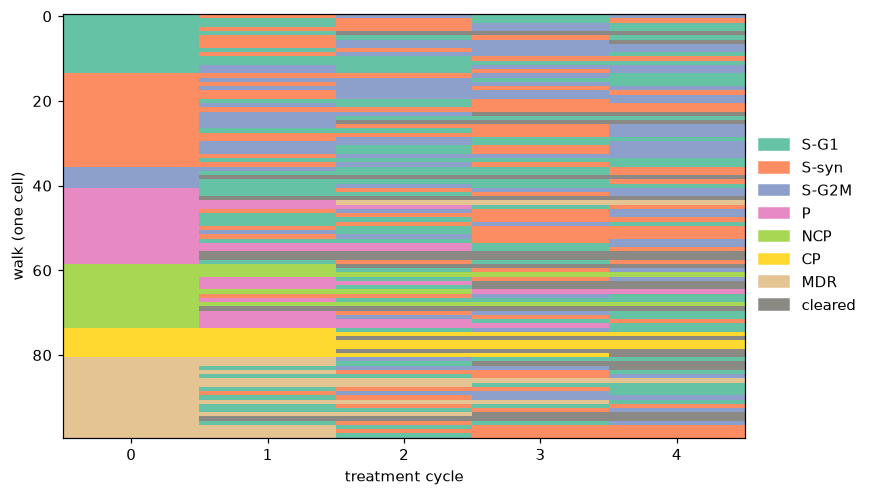

In [1140]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [1141]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

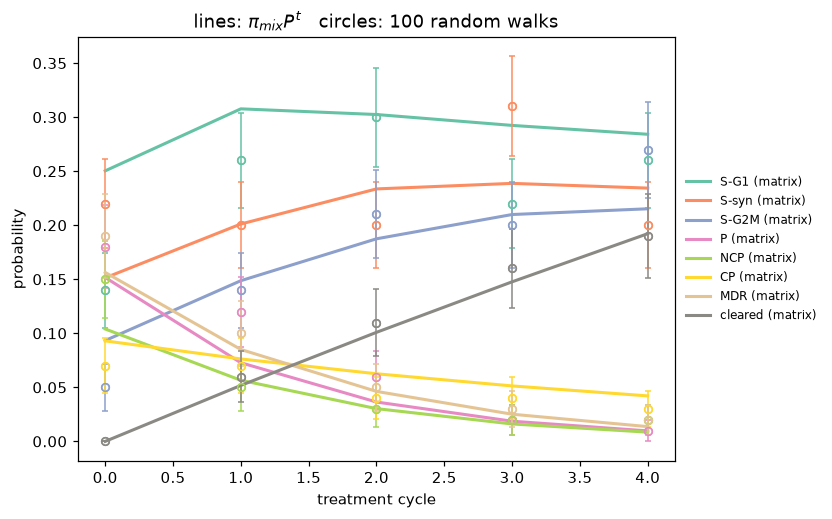

In [1142]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

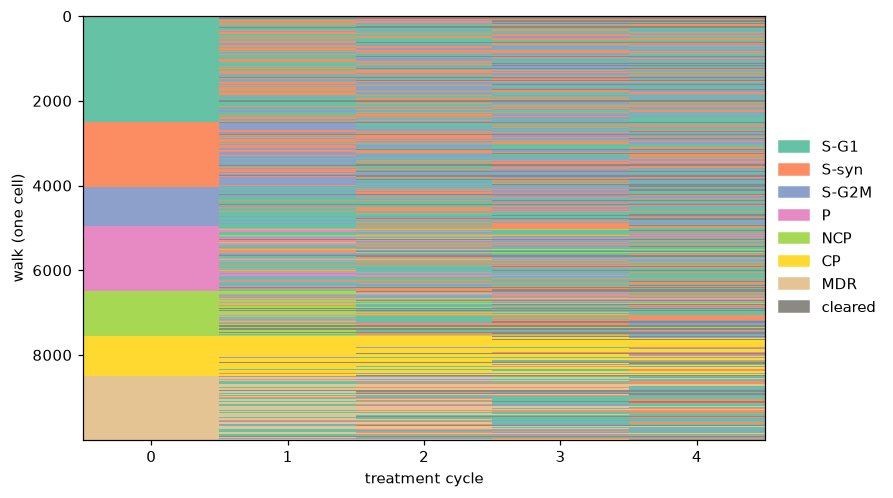

In [1143]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

In [1144]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

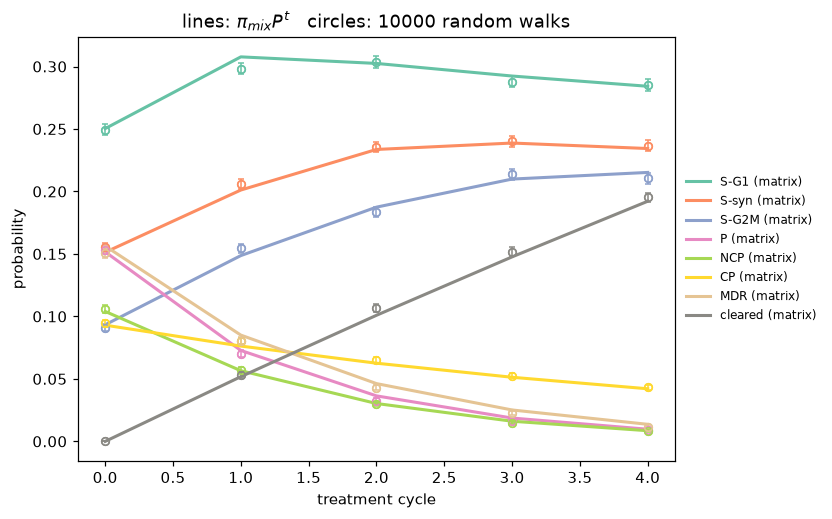

In [1145]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

The gap between the circles and lines rapidly decrease. Fix a state and a treatment cycle. Consider the random indicator variable, which is 1 if a walks ends at the given state at the given cycle, and 0 if does not end at that state. The line's value at the point represents the true probability of the walk ending at the given state at the given cycle, (which is also the expectation of the constructed indicator variable). Alternatively, our point represents a size $N$ sample mean of our indicator variable. The law of large numbers says that our sample mean approaches the population expectation as $N$ increases. Thus, $N$ increasing from $100$ to $10000$ reflects this convergence, which is symbolized by the point approaching the line. 

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [1146]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

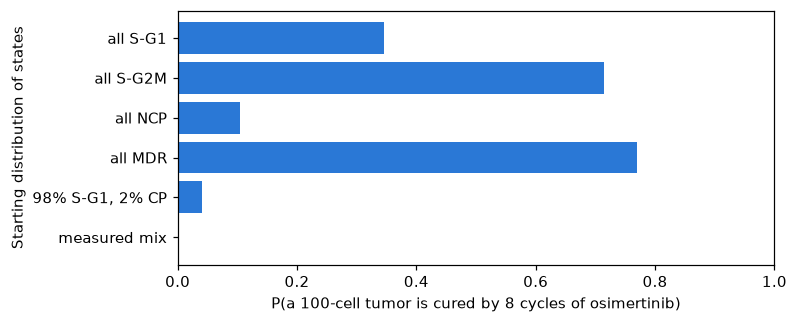

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.345,1.090,0.000
all S-G2M,0.715,0.345,0.000
all NCP,0.105,2.175,0.000
all MDR,0.770,0.255,0.000
"98% S-G1, 2% CP",0.040,3.285,0.642
measured mix,0.000,10.470,0.910


In [1147]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi_n, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

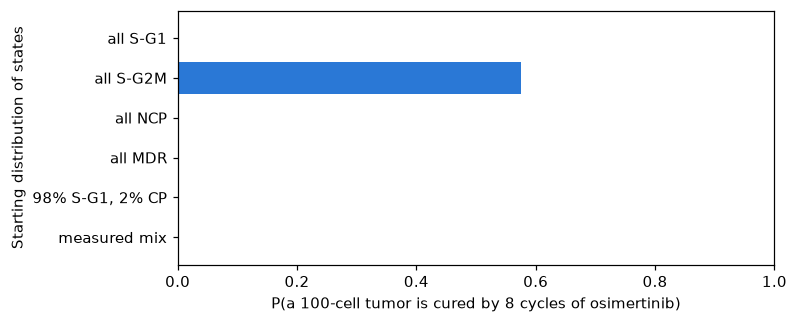

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.115,0.0
all S-G2M,0.575,0.545,0.0
all NCP,0.000,6.970,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.000,7.015,0.0
measured mix,0.000,19.165,0.0


In [1148]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc_n, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

Note that the start condition is misleading. We are drawing from a distribution that looks like start, but we don't guarantee that this is what our tumor distribution will look like for the 100 in a given tumor. This doesn't matter for the pure states, but, for instance, $98\%$ S-G1 and $2\%$ CP does not mean our original tumor is composed that way. Instead, we are drawing each cell from this distribution, meaning its possible to have a starting tumor of all S-G1, for instance. Otherwise, it would never be possible for this S-G1/CP state to be resolved by Osimertinib.

We are witnessing domination by Ositernib. From every simulation start, Osimertinib has a higher empirical clearance probability (and by a signficant margin), except for the measured mix; its mean surviving cells is also smaller. There are several reasons why this is the case. One is by design. This set of test suites favors Ostinerib, since we (unexplainably) test a pure MDR state but not a pure CP state? Even if we remove these two unfair start states, Ostinerib consistently dominates. Conceptually, the reason is simple; Ostinerib never introduces problems (CP) it cannot solve, meaning that, as long as CP isn't in the initial tumor, its only obstacle is clearing the alive cells, and it gets 8 tries to do so for each cell. The same cannot be said for docetaxel. Indeed, docetaxel can introduce problems (MDR) it cannot solve at a non-negligible rate, meaning docetaxel must do more in a sense; it must clear AND avoid introducing any MDR along the way. In effect, each cell gets fewer than 8 tries to clear on average, since many cells will face the unfortunate fate of MDR earlier. Since the rate of clearance between the two is of a similar order, fewer clearance tries clearly disadvantages docetaxel.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In my scheme, x cycles means that the given treatment strategy ran x non-holiday treatments. Thus, x cycles does not neccesarily imply x steps. Since DH only runs one non-holiday treatment per two steps, it requires double the steps to achieve the same total number of non-holiday treatments as a strategy that applies non-holiday treatment on every step. This is a modeling decision. Either we assume that x cycles means x steps (meaning all x cycle strategies are equal in time but possibly very unequal in total non-holiday treatments applied) OR we assume that x cycles means x non-holiday treatments (meaning all x cycle strategies are equal in non-holiday treatmenets applied but not in time taken). I think treatment equality is more important to prioritize, and so my decision reflects this.

In [1149]:
def random_walk_sched(start, mats, n_steps, rng):
    '''One step is one cycle applied'''
    # Initalize path
    path = [start]

    # Take a step
    for k in range(n_steps):
        # Add a new step based on current position
        # choose appropriate matrix depending on step + treatment
        path.append(step(path[-1], mats[k % len(mats)], rng))
    
    return path

def resistor_state(walk):
    '''1 if the walk is in P or NCP for 3 consecutive cycles'''
    # Fix a starting position
    for j in range(len(walk) - 2):
        # Does the 3 window starting from index j satisfy resistor?
        if all(OUTCOMES[walk[j + t]] in ["P", "NCP"] for t in range(3)):
            return 1
    return 0

def persister_cells(pi0, mats, n_cells, n_steps):
    '''Return proportion of cells in tumor with resistor states present'''
    # Intialize starting positions
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)

    # Perform a walk from each starting position with the specified steps
    walks = [random_walk_sched(int(s0), mats, n_steps, rng) for s0 in starts]

    # Compute resistor paths, return proportion of resistor walks
    return np.mean([resistor_state(w) for w in walks])

def trial(pi0, n_cells, n_cycles, n_tumors, treatment):
    # Extract matrices and steps per dose
    mats, steps_per_dose = treatments[treatment]

    # For each tumor, simulate the cell walks and return proportion of resistor cells
    prop_tumors = np.array([persister_cells(pi0, mats, n_cells, n_cycles * steps_per_dose)
                            for _ in range(n_tumors)])

    # Compute proportion of tumors with over 10% resistor cells
    over = prop_tumors > 0.10
    p_hat = over.mean()

    # Compute sem + sem interval
    sem = over.std(ddof=1) / np.sqrt(n_tumors)
    sem_interval = [p_hat - sem, p_hat + sem]

    # Compute 95% CI
    ci = [p_hat - 1.96 * sem, p_hat + 1.96 * sem]

    # Display results
    return {
        "Treatment": treatment,
        "Cycles": n_cycles,
        "Point Estimate": p_hat,
        "sem_interval": [round(sem_interval[0], 3), round(sem_interval[1], 3)],
        "95% CI": [round(ci[0], 3), round(ci[1], 3)],
    }

    # For visual ease
    res["Above/Below Null"] = "Neither" if not res["Reject Null?"] else ("Above" if p_hat > null_p else "Below")

    return res


# Mapping of treatments to their matrices
treatments = {
    "OSI": ([P_osi_n],          1),
    "DOC": ([P_doc_n],          1),
    "DO":  ([P_osi_n, P_doc_n], 1), 
    "DH":  ([P_doc_n, P_hol_n], 2),  
}
N_cells = 1000
N_tumors = 100
cycles = [8, 12, 16]

res = [trial(pi_mix, N_cells, c, N_tumors, t) for t in treatments for c in cycles]
res_df = pd.DataFrame(res)
res_df

,Treatment,Cycles,Point Estimate,sem_interval,95% CI
0,OSI,8,0.97,"[0.953, 0.987]","[0.936, 1.004]"
1,OSI,12,0.92,"[0.893, 0.947]","[0.867, 0.973]"
2,OSI,16,0.96,"[0.94, 0.98]","[0.921, 0.999]"
3,DOC,8,0.19,"[0.151, 0.229]","[0.113, 0.267]"
4,DOC,12,0.11,"[0.079, 0.141]","[0.048, 0.172]"
5,DOC,16,0.22,"[0.178, 0.262]","[0.138, 0.302]"
6,DO,8,0.72,"[0.675, 0.765]","[0.632, 0.808]"
7,DO,12,0.66,"[0.612, 0.708]","[0.567, 0.753]"
8,DO,16,0.70,"[0.654, 0.746]","[0.61, 0.79]"
9,DH,8,0.67,"[0.623, 0.717]","[0.577, 0.763]"


<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

In [1150]:
pi_mix

array([0.25033333, 0.15133333, 0.09333333, 0.15166667, 0.104     ,
       0.093     , 0.15633333, 0.        ])

In [1151]:
OUTCOMES

['S-G1', 'S-syn', 'S-G2M', 'P', 'NCP', 'CP', 'MDR', 'cleared']

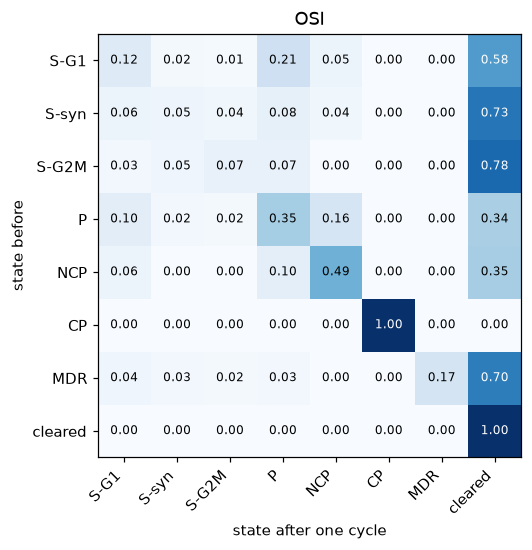

In [1155]:
show_matrix(P_osi, title="OSI")

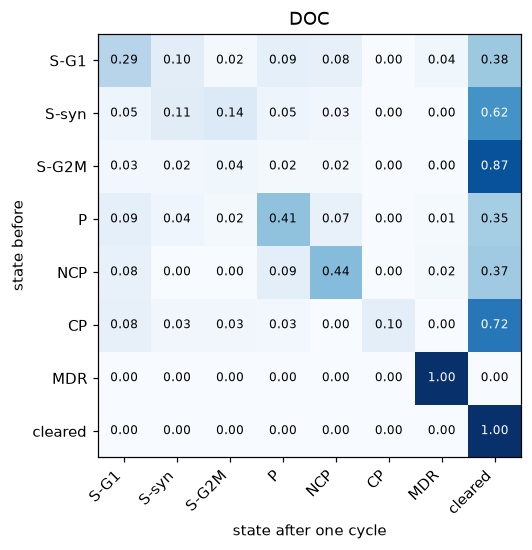

In [1154]:
show_matrix(P_doc, title="DOC")

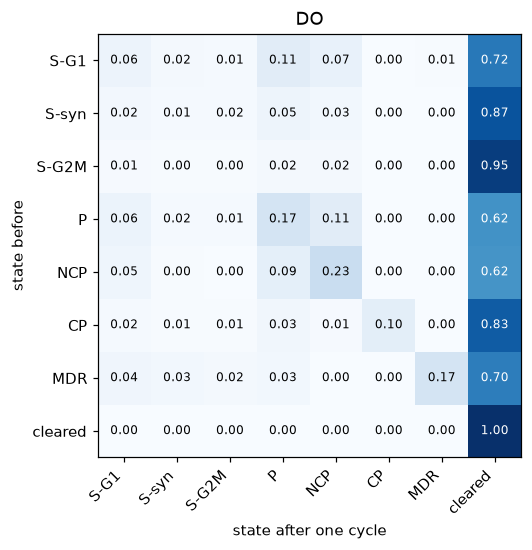

In [1153]:
show_matrix(P_doc @ P_osi, title="DO")

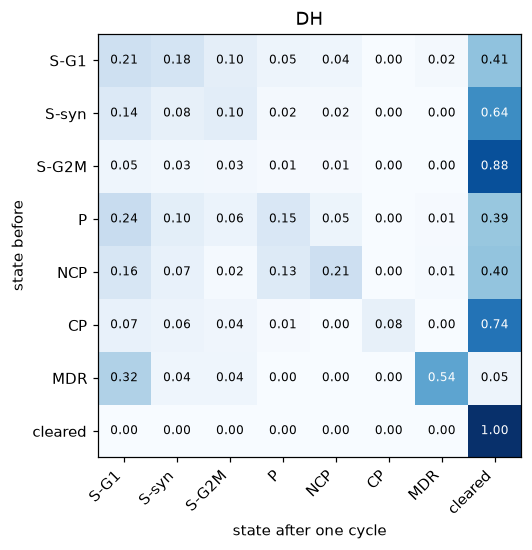

In [1156]:
show_matrix(P_doc @ P_hol, title="DH")

As the above table shows, there is significant variability in the percentage of tumors with more than $10%$ permenantly resistant cells under the various treatments, and there are essentially three flights of performers (based on confidence intervals). The worst treatment appears to be osi (with point estimates of 0.97, 0.92, snd 0.96 across the varying cycles). Its performance is incredibly poor compared to the others. Next, we have the mixed treatments (DO and DH), whose point estimates are (0.72, 0.66, 0.7) and (0.67, 0.69, 0.65), respectively. Finally, we have the best performer, doc, whose point estimates were 0.19, 0.11, and 0.22. We can explain this differences in several ways. First, it is important to identify the role of our starting distribution, pi_mix. Pi_mix has almost double the frequency of MDR than CP. Since neither of these states are considered resistant in this exercise but are absorbing for their respective treatments (MDR for doce, CP for osi), there is actually an advantage to funneling into them. In this way, docetaxel is essentially spotted almost double the absorbing state starts, which are guaranteed to not be resistant. Originally presented as a flaw, docetaxel is also MDR generative (and osi is NOT CP generative), meaning a small number of states can arrive in MDR under docetaxel, behaving like a defacto clearance. Also, looking back at the transition matrices, several additional patterns are worth identifying. First, relative to doc, osi funnels more S-G1, S-syn, and S-G2M states into P and NCP states. The respective probabilities (S-G1, S-syn, and S-G2M) are 0.26, 0.12, and 0.07 as compared to 0.17, 0.08, 0.04. The largest discrepency occurs in the S-G1 state, and this happens to be the most frequent starting state. For osi, if you are already in P, the probability of remaining in P or NCP is 0.51 as compared to doce's 0.48. Similarly, if you are already in NCP, the probability of remaining in P or NCP is 0.59 as compared to doce's 0.53. It is clear, then, that doce brings non-resistant states into resistant states at a higher rate, and they keep them in the resistant state at a higher rate. The DO treatment performing as it did is sort of surprising. When we look at its transition matrix, we see that it doesn't actually funnel many cells into P and NCP (relative to the pure treatments), cells don't stick in these states at as high of a frequency, though it has a relatively high rate of clearance. However, unlike the pure treatments, which have a defacto second clearance state, neither CP or MDR is absorbing. Roughly $17\%$ of CP states and $30\%$ of MDR states have a chance to escape and possibly become resistant. The same behavior appears to be happening with DH, but more extremely; we see that it actually funnels even fewer cells into P and NCP (relative to the other treatments), cells stick in these states at the lowest frequency, and it has a moderate level of clearance. However, its CP and MDR states are even further from absorbing; roughly $26\%$ of CP cells and $95\%$ of MDR can escape and become resistant. Conceptually, these mixed treatments don't slam the door on cells (through high clearance and absorption) like the pure treatment doc does, and little chance of idling in resistant states beats no chance of idling in resistant states every day of the week. 

(A separate implementation difference that may also affect results is that I considered paths after each treatment application. Accordingly, the simulation is only really seeing the patterns in the mixed tables above after two cycles, not one.)

As we hold the treatment fixed and increase the cycles, results are not exactly the same, but they more or less remain in the same ballpark; there is not a uniform trend, with the point estimate sometimes increasing then decreasing or decreasing then increasing with more trials. In all of these cases, the $95\%$ CI overlap signficantly, meaning the differences are not statistically significant. One conceptual insight from this is that by four cycles, the fate of each cell has more or less been sealed; it has either died or it has idled in P and NCP sufficiently long enough to become resistant. This insight agrees with our earlier assesment of treatment cycles, where a high ($ \approx 90\%$) level of clearance was achieved by four cycles, and, after, its increase slowed. 